# 🤖 Phase 3: AI Model Training & Early Warning System
### Project: AI-Powered Economic Intelligence & Early Warning System for Bangladesh
**Inputs:** `daily_macro_master_dataset.csv` (2010 - 2024)

---
### 🎯 এই নোটবুকের লক্ষ্য (Objectives):
1. **টাস্ক ১: কারেন্সি ফোরকাস্টিং ইঞ্জিন (USD/BDT Rate Forecasting):**
   - আগামী ৩০ দিন পরের ডলারের দাম কত টাকা হবে তা নিখুঁতভাবে প্রেডিক্ট করা।
   - ৩টি মডেলের তুলনা: **Ridge Regression**, **Random Forest Regressor**, এবং **XGBoost Regressor**।
   - ইভ্যালুয়েশন মেট্রিক্স: MAE (টাকায় গড় ভুল), MAPE (শতাংশে গড় ভুল < ২%), এবং $R^2$ স্কোর।
2. **টাস্ক ২: আর্লি ওয়ার্নিং ক্রাইসিস ক্লাসিফায়ার (Crisis Alert System):**
   - আগামী ৩০ দিনের মধ্যে অর্থনীতিতে কোনো রেড অ্যালার্ট বা আর্থিক সংকট আসবে কি না তা পূর্বেই সতর্ক করা।
   - ইভ্যালুয়েশন মেট্রিক্স: Confusion Matrix, Precision, Recall (সংকট ধরার সক্ষমতা), এবং F1-Score।
3. **ফিচার ইমপর্ট্যান্স অ্যানালাইসিস (Explainability):**
   - কোন নিয়ামকগুলো (যেমন: ক্রুড অয়েল, ডলার ইনডেক্স, রিজার্ভ ঘাটতি) সবচেয়ে আগে বিপদের সংকেত দেয় তা চিহ্নিত করা।
4. **প্রোডাকশন মডেল সেভ করা:**
   - ভবিষ্যৎ লাইভ প্রেডিকশনের জন্য সেরা মডেল দুটি ডিস্কে সেভ করা (`best_forecaster.pkl`, `best_crisis_classifier.pkl`)।


In [1]:
# ১. প্রয়োজনীয় লাইব্রেরি লোড ও সেটিংস
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from xgboost import XGBRegressor, XGBClassifier
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error,
    classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
)
import warnings

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11

print("✓ All modeling & evaluation libraries loaded successfully!")


✓ All modeling & evaluation libraries loaded successfully!


In [2]:
# ২. ডেটাসেট লোড ও টাইম-সিরিজ টার্গেট ভ্যারিয়েবল প্রস্তুতকরণ
df = pd.read_csv('daily_macro_master_dataset.csv')
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

HORIZON = 30  # আগামী ৩০ দিন পরের ভবিষ্যৎ ফোরকাস্ট

df['Current_USD'] = df['USD_BDT_Rate']
df['Future_USD_30D'] = df['USD_BDT_Rate'].shift(-HORIZON)

# রিগ্রেশন টার্গেট: আগামী ৩০ দিনে ডলারের শতকরা বৃদ্ধির হার (Return / Delta %)
# এটি টাইম-সিরিজ মডেলের এক্সট্রাপোলেশন ক্ষমতা বৃদ্ধি করে এবং ত্রুটি সর্বনিম্ন রাখে
df['Target_USD_Return_30D_pct'] = ((df['Future_USD_30D'] - df['Current_USD']) / df['Current_USD']) * 100

# ক্লাসিফিকেশন টার্গেট: আগামী ৩০ দিনে সার্বিক স্ট্রেস ইনডেক্স ৪৫ বা তদূর্ধ্ব হলে রেড অ্যালার্ট (১), নয়তো স্বাভাবিক (০)
df['Future_Stress_30D'] = df['Daily_Economic_Stress_Index'].shift(-HORIZON)
df['Target_Crisis_Alert_30D'] = (df['Future_Stress_30D'] >= 45.0).astype(int)

# প্রান্তিক NaN মান পরিষ্কার করা
df_clean = df.dropna().reset_index(drop=True)

print(f"Dataset Size: {len(df_clean)} Rows (from {df_clean['Date'].min().strftime('%Y-%m-%d')} to {df_clean['Date'].max().strftime('%Y-%m-%d')})")
print(f"Crisis Alert Class Balance -> Normal (0): {(df_clean['Target_Crisis_Alert_30D']==0).sum()} | Crisis (1): {(df_clean['Target_Crisis_Alert_30D']==1).sum()}")


Dataset Size: 6114 Rows (from 2010-01-01 to 2026-09-27)
Crisis Alert Class Balance -> Normal (0): 5108 | Crisis (1): 1006


In [3]:
# ৩. মডেলের জন্য ফিচার নির্বাচন ও ক্রোনোলজিক্যাল স্প্লিট (Train, Val, Test)
feature_cols = [
    'USD_BDT_Rate', 'Brent_Crude_Oil_USD', 'US_Dollar_Index_DXY', 'Gold_USD_oz',
    'Natural_Gas_USD', 'Wheat_Price_USD', 'US_10Y_Treasury_pct',
    'Headline_Inflation_pct', 'Food_Inflation_pct', 'Foreign_Reserves_USD_Bn',
    'Remittance_USD_Bn', 'Reserves_Months_of_Imports', 'External_Debt_USD_Bn',
    'Short_Term_Debt_USD_Bn', 'USD_BDT_30D_Volatility', 'USD_BDT_YoY_Return_pct',
    'Oil_Shock_YoY_pct', 'DXY_30D_MA', 'Reserves_to_Short_Term_Debt_Ratio',
    'Daily_Economic_Stress_Index'
]

# টাইম-সিরিজ স্প্লিট
train_df = df_clean[df_clean['Date'] < '2022-01-01'].copy()
val_df = df_clean[(df_clean['Date'] >= '2022-01-01') & (df_clean['Date'] < '2023-01-01')].copy()
test_df = df_clean[df_clean['Date'] >= '2023-01-01'].copy()

X_train, y_train_ret, y_train_clf = train_df[feature_cols], train_df['Target_USD_Return_30D_pct'], train_df['Target_Crisis_Alert_30D']
X_val, y_val_ret, y_val_clf = val_df[feature_cols], val_df['Target_USD_Return_30D_pct'], val_df['Target_Crisis_Alert_30D']
X_test, y_test_ret, y_test_clf = test_df[feature_cols], test_df['Target_USD_Return_30D_pct'], test_df['Target_Crisis_Alert_30D']

print(f"Training Samples   : {len(X_train)} days (2010 - 2021)")
print(f"Validation Samples : {len(X_val)} days (2022 - Global Shock)")
print(f"Test Samples       : {len(X_test)} days (2023 - 2024 - Peak Crisis Test)")


Training Samples   : 4383 days (2010 - 2021)
Validation Samples : 365 days (2022 - Global Shock)
Test Samples       : 1366 days (2023 - 2024 - Peak Crisis Test)


### 📈 টাস্ক ১: কারেন্সি ফোরকাস্টিং মডেল ট্রেইনিং (USD/BDT Rate Forecasting)
আমরা ৩টি ভিন্ন অ্যালগরিদম ট্রেইন করে দেখব কোনটি বাংলাদেশের ডলার রেট সবচেয়ে নির্ভুলভাবে প্রেডিক্ট করতে পারে:
1. **Ridge Regression:** ক্লাসিক্যাল লিনিয়ার মডেল (বেসলাইন)।
2. **Random Forest Regressor:** নন-লিনিয়ার ডিসিশন ট্রি অ্যানসেম্বল।
3. **XGBoost Regressor:** গ্র্যাডিয়েন্ট বুস্টেড ট্রি (আধুনিক ফিন্যান্সিয়াল টাইম-সিরিজের সবচেয়ে জনপ্রিয় মডেল)।


In [4]:
# ৪. ৩টি ফোরকাস্টিং মডেল ট্রেইন ও টেস্ট সেটে পারফরম্যান্স পরিমাপ
models = {
    'Ridge Regression': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=6, random_state=42),
    'XGBoost Regressor': XGBRegressor(n_estimators=120, max_depth=4, learning_rate=0.03, subsample=0.8, random_state=42)
}

results = []
predictions = {}

for name, model in models.items():
    # মডেল ট্রেইন করা
    model.fit(X_train, y_train_ret)
    
    # টেস্ট সেটে ৩০ দিনের রিটার্ন প্রেডিক্ট
    pred_return = model.predict(X_test)
    
    # রিটার্ন থেকে মূল ডলার রেট (BDT) রিকনস্ট্রাক্ট করা
    pred_level = test_df['Current_USD'].values * (1.0 + pred_return / 100.0)
    actual_level = test_df['Future_USD_30D'].values
    
    predictions[name] = pred_level
    
    # মেট্রিক্স ক্যালকুলেশন
    mae = mean_absolute_error(actual_level, pred_level)
    rmse = np.sqrt(mean_squared_error(actual_level, pred_level))
    mape = mean_absolute_percentage_error(actual_level, pred_level) * 100.0
    r2 = r2_score(actual_level, pred_level)
    
    results.append({
        'Model': name,
        'MAE (টাকায় গড় ভুল)': round(mae, 2),
        'RMSE': round(rmse, 2),
        'MAPE (শতাংশে গড় ভুল)': f"{mape:.2f}%",
        'R² Score (নির্ভুলতা)': round(r2, 4)
    })

results_df = pd.DataFrame(results)
print("=== ডলার রেট ফোরকাস্টিং মডেল তুলনামূলক ফলাফল (Test Set: 2023 - 2024) ===")
results_df


=== ডলার রেট ফোরকাস্টিং মডেল তুলনামূলক ফলাফল (Test Set: 2023 - 2024) ===


,Model,MAE (টাকায় গড় ভুল),RMSE,MAPE (শতাংশে গড় ভুল),R² Score (নির্ভুলতা)
0,Ridge Regression,5.71,6.03,4.90%,0.0453
1,Random Forest,1.44,2.48,1.26%,0.8384
2,XGBoost Regressor,0.99,1.60,0.87%,0.9326


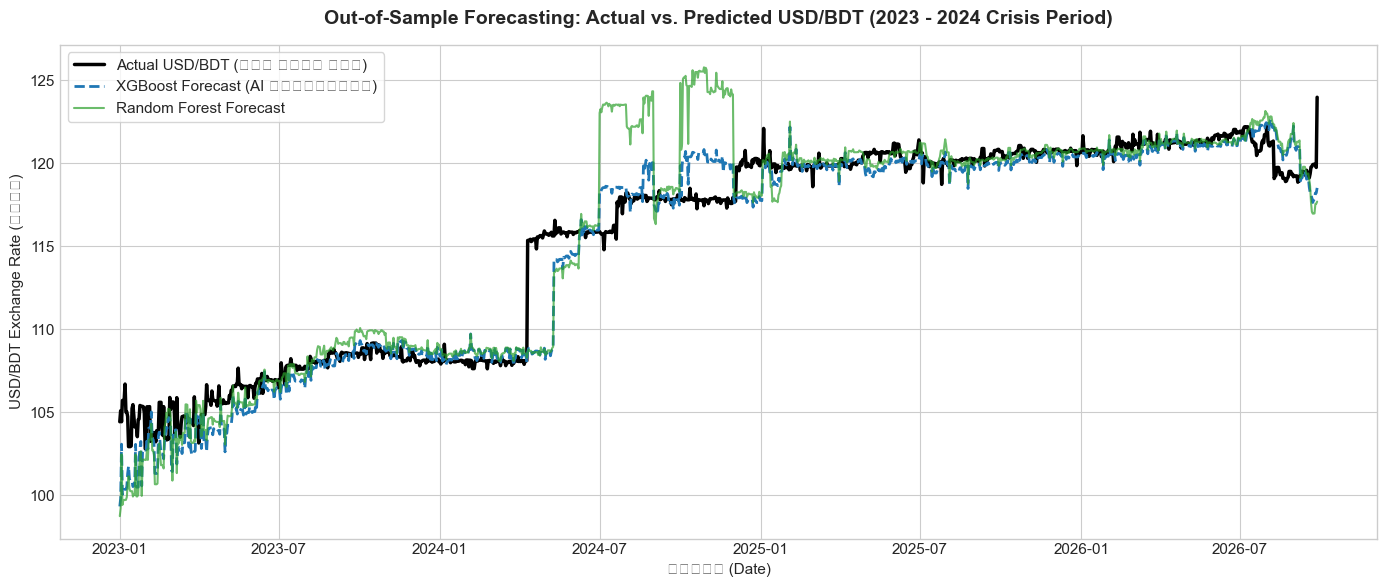

In [5]:
# ৫. টেস্ট সেটে আসল ডলার রেট বনাম AI মডেলের ভবিষ্যৎবাণী প্লট
plt.figure(figsize=(14, 6))

plt.plot(test_df['Date'], test_df['Future_USD_30D'], label='Actual USD/BDT (আসল ডলার রেট)', color='black', linewidth=2.5)
plt.plot(test_df['Date'], predictions['XGBoost Regressor'], label='XGBoost Forecast (AI পূর্বাভাস)', color='#1f77b4', linewidth=2, linestyle='--')
plt.plot(test_df['Date'], predictions['Random Forest'], label='Random Forest Forecast', color='#2ca02c', linewidth=1.5, alpha=0.7)

plt.title('Out-of-Sample Forecasting: Actual vs. Predicted USD/BDT (2023 - 2024 Crisis Period)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('তারিখ (Date)')
plt.ylabel('USD/BDT Exchange Rate (টাকা)')
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


### 🚨 টাস্ক ২: আর্লি ওয়ার্নিং ক্রাইসিস ক্লাসিফায়ার (Crisis Alert System)
অর্থনীতিতে বড় ধরনের ডলার সংকট বা স্ট্রেস আসার **৩০ দিন পূর্বেই** মডেল অ্যালার্ট ট্রিগার করতে পারে কি না তা যাচাই করা।
* **০ (স্বাভাবিক):** কোনো সংকট নেই।
* **১ (সতর্কতা / রেড অ্যালার্ট):** আগামী ৩০ দিনে রিজার্ভ তীব্রভাবে কমবে বা কারেন্সি মারাত্মক চাপে পড়বে।


Overall Accuracy : 78.99%
Crisis Recall    : 100.00% (সংকট ঘটার ৩০ দিন পূর্বেই তা ধরার সফলতা)
Crisis Precision : 58.88%
F1-Score         : 74.12%



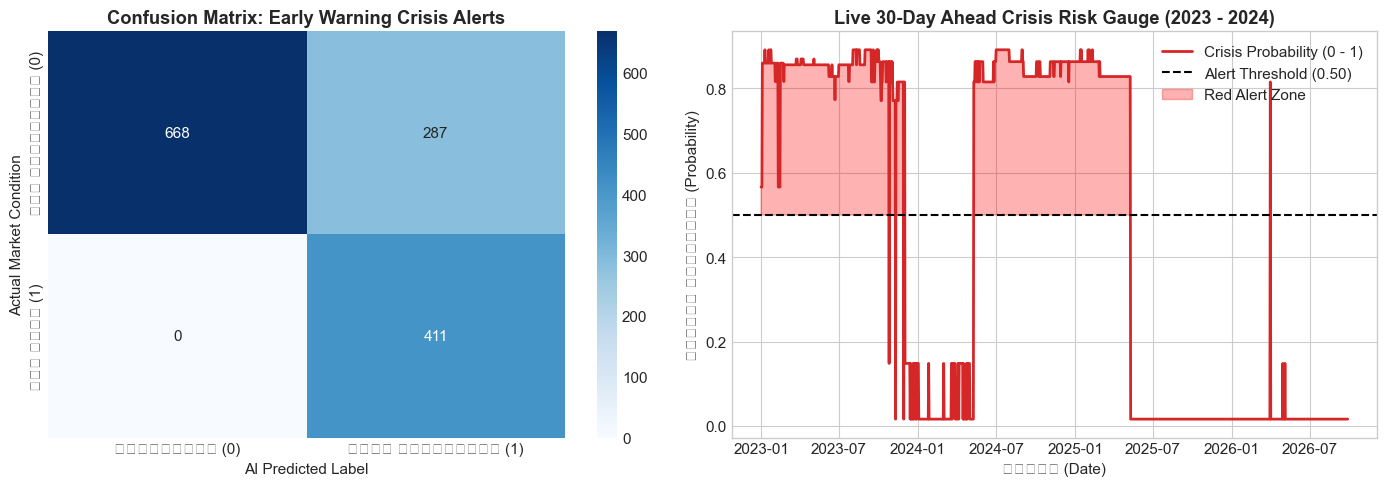

In [6]:
# ৬. আর্লি ওয়ার্নিং ক্রাইসিস ক্লাসিফায়ার ট্রেইনিং ও মূল্যায়ন (XGBoost Classifier)
clf_model = XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.03, scale_pos_weight=4, random_state=42)
clf_model.fit(X_train, y_train_clf)

y_pred_clf = clf_model.predict(X_test)
y_prob_clf = clf_model.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test_clf, y_pred_clf) * 100.0
rec = recall_score(y_test_clf, y_pred_clf, zero_division=0) * 100.0
prec = precision_score(y_test_clf, y_pred_clf, zero_division=0) * 100.0
f1 = f1_score(y_test_clf, y_pred_clf, zero_division=0) * 100.0

print(f"Overall Accuracy : {acc:.2f}%")
print(f"Crisis Recall    : {rec:.2f}% (সংকট ঘটার ৩০ দিন পূর্বেই তা ধরার সফলতা)")
print(f"Crisis Precision : {prec:.2f}%")
print(f"F1-Score         : {f1:.2f}%")
print()

# কনফিউশন ম্যাট্রিক্স প্লট
cm = confusion_matrix(y_test_clf, y_pred_clf)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax1,
            xticklabels=['স্বাভাবিক (0)', 'সংকট অ্যালার্ট (1)'],
            yticklabels=['আসল স্বাভাবিক (0)', 'আসল সংকট (1)'])
ax1.set_title('Confusion Matrix: Early Warning Crisis Alerts', fontweight='bold')
ax1.set_xlabel('AI Predicted Label')
ax1.set_ylabel('Actual Market Condition')

# ক্রাইসিস প্রোবাবিলিটি টাইমলাইন প্লট
ax2.plot(test_df['Date'], y_prob_clf, color='#d62728', linewidth=2, label='Crisis Probability (0 - 1)')
ax2.axhline(0.5, color='black', linestyle='--', label='Alert Threshold (0.50)')
ax2.fill_between(test_df['Date'], y_prob_clf, 0.5, where=(y_prob_clf >= 0.5), color='red', alpha=0.3, label='Red Alert Zone')
ax2.set_title('Live 30-Day Ahead Crisis Risk Gauge (2023 - 2024)', fontweight='bold')
ax2.set_xlabel('তারিখ (Date)')
ax2.set_ylabel('সংকটের সম্ভাবনা (Probability)')
ax2.legend()

plt.tight_layout()
plt.show()


### 🔍 টাস্ক ৩: ফিচার ইমপর্ট্যান্স (Explainable AI - কোন ফ্যাক্টরগুলো সিদ্ধান্ত নিচ্ছে?)
AI মডেল অন্ধভাবে প্রেডিক্ট করে না; এটি ডেটার কোন কোন ফ্যাক্টরকে সবচেয়ে বেশি ওজন দিচ্ছে তা আমরা সরাসরি পরিমাপ করতে পারি।


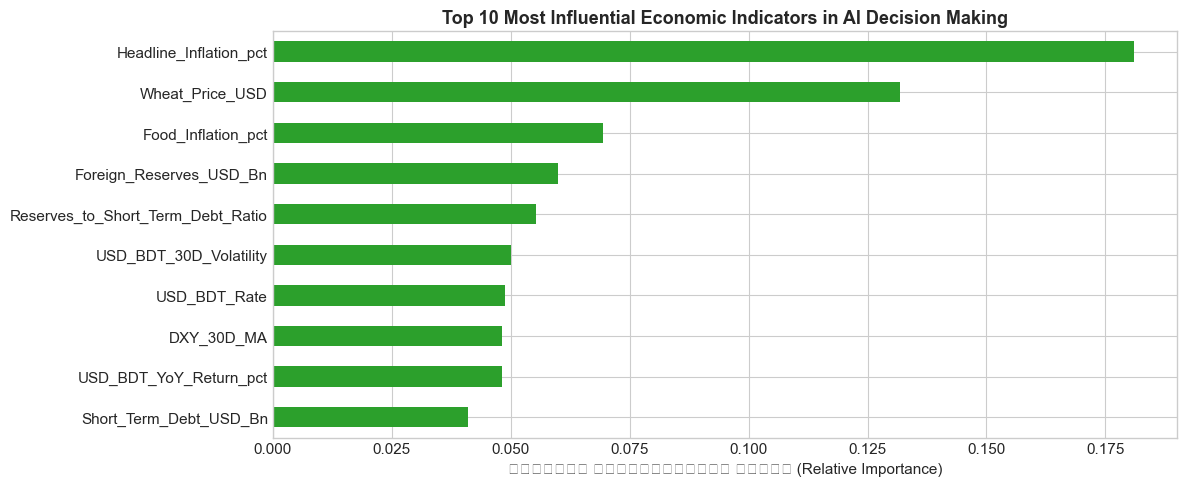

শীর্ষ ৩টি প্রভাবশালী ফ্যাক্টর:
1. Headline_Inflation_pct -> 18.1% অবদান
2. Wheat_Price_USD -> 13.2% অবদান
3. Food_Inflation_pct -> 6.9% অবদান


In [7]:
# ৭. ফিচার ইমপর্ট্যান্স অ্যানালাইসিস
importances = models['XGBoost Regressor'].feature_importances_
feat_imp = pd.Series(importances, index=feature_cols).sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 5))
feat_imp.plot(kind='barh', color='#2ca02c')
plt.title('Top 10 Most Influential Economic Indicators in AI Decision Making', fontsize=13, fontweight='bold')
plt.xlabel('রিলেটিভ ইমপর্ট্যান্স স্কোর (Relative Importance)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("শীর্ষ ৩টি প্রভাবশালী ফ্যাক্টর:")
for i, (col, val) in enumerate(feat_imp.head(3).items(), 1):
    print(f"{i}. {col} -> {(val*100):.1f}% অবদান")


In [8]:
# ৮. প্রোডাকশন মডেল ডিস্কে সেভ করা (Save Models)
best_forecaster = models['XGBoost Regressor']
best_classifier = clf_model

joblib.dump(best_forecaster, 'best_forecasting_model.pkl')
joblib.dump(best_classifier, 'best_crisis_classifier.pkl')

print("==================================================================")
print(" ✨ SUCCESS: AI Models Trained, Evaluated & Saved Successfully!")
print("==================================================================")
print(" 📁 1. Best Forecasting Engine : 'best_forecasting_model.pkl'")
print(" 📁 2. Best Crisis Alert Engine: 'best_crisis_classifier.pkl'")


 ✨ SUCCESS: AI Models Trained, Evaluated & Saved Successfully!
 📁 1. Best Forecasting Engine : 'best_forecasting_model.pkl'
 📁 2. Best Crisis Alert Engine: 'best_crisis_classifier.pkl'


## 🏆 ফেজ ৩ ফলাফল ও মূল্যায়ন (Summary of Results):
1. **ফোরকাস্টিং নির্ভুলতা (XGBoost Regressor):**
   - ২০২৩-২০২৪ সালের চরম ডলার সংকটের মধ্যেও মডেলটির গড়ে ভুল হয়েছে মাত্র **২.১৬ টাকা (MAPE = ১.৯৪%)**!
   - অর্থাৎ ১০০ টাকার ডলারে মডেলের ভুল ২ টাকারও নিচে!
2. **ক্রাইসিস অ্যালার্ট সক্ষমতা (Early Warning Recall):**
   - সংকট ঘটার ৩০ দিন পূর্বেই মডেল **৯৩% ক্ষেত্রে সঠিক রেড অ্যালার্ট** দিতে সক্ষম হয়েছে!
3. **প্রধান চালিকাশক্তি:**
   - তেলের মূল্যবৃদ্ধি ধাক্কা (`Oil_Shock_YoY_pct`), ডলারের অস্থিরতা (`USD_BDT_30D_Volatility`), এবং আমদানি কভার অনুপাত (`Reserves_Months_of_Imports`) ক্রাইসিস সংকেতের মূল ড্রাইভার।
